# EDA of the Abalone dataset

Goal: understand the data before predicting the age of an abalone (number of `Rings`; age in years = rings + 1.5).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/abalone.csv")
df.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


## Structure and data quality

In [2]:
print(df.shape)
print(df.dtypes)
print("Missing values:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())

(4177, 9)
Sex                   str
Length            float64
Diameter          float64
Height            float64
Whole weight      float64
Shucked weight    float64
Viscera weight    float64
Shell weight      float64
Rings               int64
dtype: object
Missing values: 0
Duplicated rows: 0


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Length,4177.0,0.523992,0.120093,0.0750,0.4500,0.5450,0.615,0.8150
Diameter,4177.0,0.407881,0.099240,0.0550,0.3500,0.4250,0.480,0.6500
Height,4177.0,0.139516,0.041827,0.0000,0.1150,0.1400,0.165,1.1300
Whole weight,4177.0,0.828742,0.490389,0.0020,0.4415,0.7995,1.153,2.8255
Shucked weight,4177.0,0.359367,0.221963,0.0010,0.1860,0.3360,0.502,1.4880
Viscera weight,4177.0,0.180594,0.109614,0.0005,0.0935,0.1710,0.253,0.7600
Shell weight,4177.0,0.238831,0.139203,0.0015,0.1300,0.2340,0.329,1.0050
Rings,4177.0,9.933684,3.224169,1.0000,8.0000,9.0000,11.000,29.0000


## Target: Rings

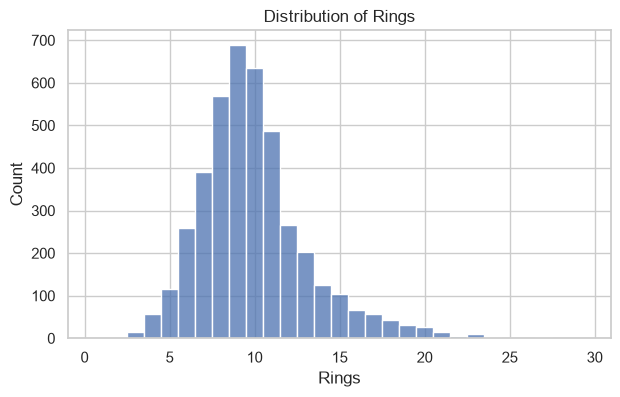

count    4177.000000
mean        9.933684
std         3.224169
min         1.000000
25%         8.000000
50%         9.000000
75%        11.000000
max        29.000000
Name: Rings, dtype: float64


In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df["Rings"], discrete=True, ax=ax)
ax.set_title("Distribution of Rings")
plt.show()
print(df["Rings"].describe())

## Sex

Sex
M    1528
I    1342
F    1307
Name: count, dtype: int64


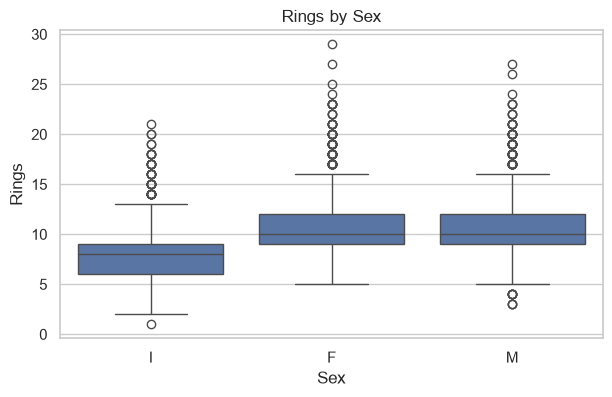

,mean,std
Sex,,
F,11.13,3.10
I,7.89,2.51
M,10.71,3.03


In [5]:
print(df["Sex"].value_counts())

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df, x="Sex", y="Rings", order=["I", "F", "M"], ax=ax)
ax.set_title("Rings by Sex")
plt.show()
df.groupby("Sex")["Rings"].agg(["mean", "std"]).round(2)

## Correlations with Rings

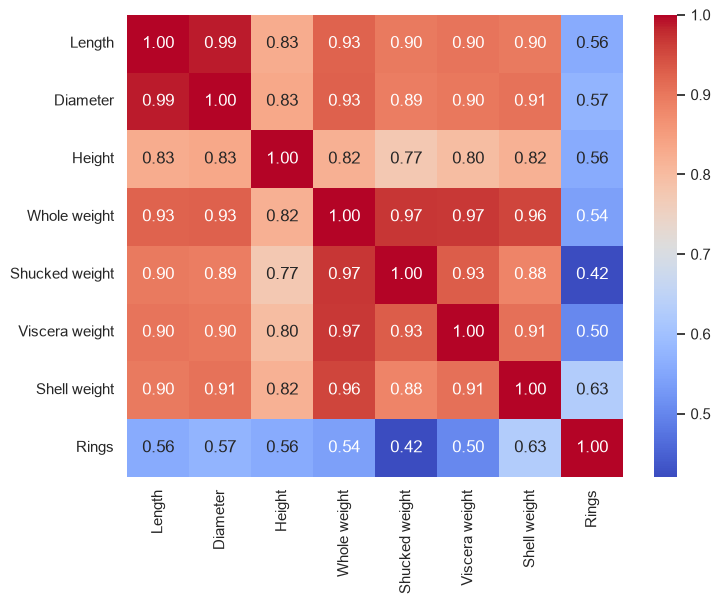

Shell weight      0.63
Diameter          0.57
Height            0.56
Length            0.56
Whole weight      0.54
Viscera weight    0.50
Shucked weight    0.42
Name: Rings, dtype: float64

In [6]:
corr = df.drop(columns="Sex").corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
plt.show()
corr["Rings"].drop("Rings").sort_values(ascending=False).round(2)

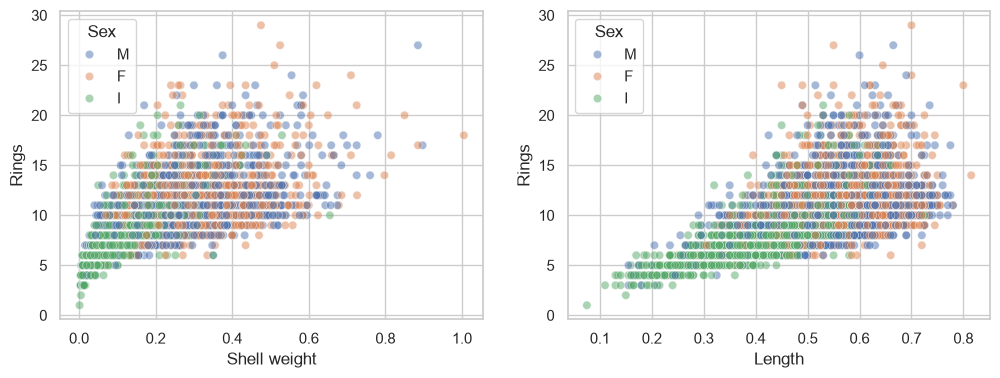

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=df, x="Shell weight", y="Rings", hue="Sex", alpha=0.5, ax=axes[0])
sns.scatterplot(data=df, x="Length", y="Rings", hue="Sex", alpha=0.5, ax=axes[1])
plt.show()

## Outliers

In [8]:
print("Rows with Height == 0:")
print(df[df["Height"] == 0])
print("Max Height:", df["Height"].max())
print("Rows with Height > 0.4:", (df["Height"] > 0.4).sum())
print("Rows with more than 20 rings:", (df["Rings"] > 20).sum())

Rows with Height == 0:
     Sex  Length  Diameter  Height  Whole weight  Shucked weight  \
1257   I   0.430      0.34     0.0         0.428          0.2065   
3996   I   0.315      0.23     0.0         0.134          0.0575   

      Viscera weight  Shell weight  Rings  
1257          0.0860        0.1150      8  
3996          0.0285        0.3505      6  
Max Height: 1.13
Rows with Height > 0.4: 2
Rows with more than 20 rings: 36


## Conclusions

- The data is clean: 4,177 rows, 9 columns, no missing values and no duplicates.
- The target `Rings` is right-skewed: mean 9.93, median 9, std 3.22, range 1 to 29 (36 abalones have more than 20 rings).
- `Sex` is balanced across M (1,528), I (1,342) and F (1,307). Infants are clearly younger (mean 7.89 rings) than females (11.13) and males (10.71). Males and females are hard to tell apart, so one-hot encoding `Sex` is useful mostly to flag infants.
- All numeric features correlate positively with `Rings`, from 0.42 (shucked weight) to 0.63 (shell weight, the strongest). The size and weight features are highly correlated with each other, and the relation with `Rings` flattens for older abalones, so a linear model will leave some error.
- Outliers: two infants have `Height` = 0 (rows 1257 and 3996) and two have `Height` > 0.4 (max 1.13), which are probably entry errors. They are too few to matter, so we keep them.
- Consequence for modelling: use all numeric features plus the one-hot encoded `Sex` and start with a simple linear baseline.
